# Отчетность по поездкам такси: ClickHouse и SQLite

Подготовка почасовой отчетности по желтому такси Нью-Йорка за январь-март 2016 года.
Нужно получить из публичной базы проверенные таблицы, сохранить их в SQLite и выяснить,
как различается время пиковых поездок между буднями и выходными в основных зонах посадки.

Результат - витрина с детализацией «дата - час посадки - зона» и отчет по сохраненным данным.
Он помогает выбрать временные и территориальные срезы для дальнейшего разбора нагрузки.

## 1. Источник и правила учета

Источник - публичный [ClickHouse Playground](https://clickhouse.com/docs/get-started/sample-datasets/playground),
таблица `default.trips`. Доступ только на чтение. Из нескольких категорий перевозок выбираю `cab_type = 'yellow'`,
чтобы отчет относился к одному виду такси. Период - с 1 января 2016 года включительно до 1 апреля,
конец не включается. В сохраненной выгрузке есть записи за все 91 календарный день.

Уникальный `trip_id` не гарантирует уникальность поездки: строки с разными идентификаторами
полностью повторяются по остальным полям. Единицей учета принимаю уникальное сочетание этих полей.
Без первичного идентификатора TLC нельзя исключить объединение физически разных поездок
с полностью одинаковыми значениями.

В отчет включаю записи с согласованными датами, длительностью от 1 секунды до 24 часов,
положительным расстоянием и положительной конечной суммой. Причины исключения назначаются
последовательно: запись получает первую подходящую причину. Ниже проверю, сохраняются ли часы
пика при ограничении длительности 6 часами.

`pickup_ntaname` - название района из обогащенного набора ClickHouse.
Это не идентификатор современного справочника TLC Taxi Zones. Пустые названия объединяю
в группу «Не определено».

`total_amount` - начисленная пассажиру сумма в долларах США.
По [словарю TLC](https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf),
она не включает наличные чаевые. Это не прибыль и не подтвержденная выручка перевозчика.
Деньги перевожу в целые центы после округления каждой записи.

In [1]:
import os
import sqlite3
import time
from datetime import datetime, timezone

import clickhouse_connect
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from tqdm import tqdm

# Задаем единый стиль графиков
sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans")


In [2]:
# Выбираем период и режим получения исходных агрегатов
period_start = "2016-01-01"
period_end = "2016-04-01"
refresh_source = False

source_dir = "data/source"
database_path = "data/taxi_reporting.sqlite"
for directory in [source_dir, "assets"]:
    os.makedirs(directory, exist_ok=True)

## 2. Extract: получение данных из ClickHouse

При `refresh_source = False` используется сохраненная выгрузка из `data/source/`.
Для обращения к серверу нужно установить `refresh_source = True`.
После изменения периода или SQL требуется новая выгрузка.

Удаление повторов, расчет длительности, проверки качества и агрегация выполняются
в ClickHouse. В Python приходит таблица с детализацией «дата - час - зона - причина отбора».
Отдельный запрос нужен для сверки дневных количеств и сумм.

`source_copies` сохраняет количество исходных копий.
Две одинаковые строки с разными `trip_id` дают одну запись с `source_copies = 2`.

In [3]:
# Группируем полные повторы и выгружаем почасовые агрегаты с признаками качества
extract_query = """
WITH unique_trips AS (
    SELECT
        * EXCEPT (trip_id),
        count() AS source_copies
    FROM default.trips
    WHERE cab_type = 'yellow'
        AND pickup_date >= {source_day:Date}
        AND pickup_date < addDays({source_day:Date}, 1)
    GROUP BY ALL
), classified AS (
    SELECT
        pickup_date AS trip_date,
        toHour(pickup_datetime) AS pickup_hour,
        trimBoth(pickup_ntaname) AS pickup_zone,
        source_copies,
        dateDiff('second', pickup_datetime, dropoff_datetime) AS duration_seconds,
        toInt64(round(ifNotFinite(toFloat64(total_amount), 0) * 100)) AS amount_cents,
        multiIf(
            pickup_date != toDate(pickup_datetime)
                OR dropoff_date != toDate(dropoff_datetime), 'date_mismatch',
            duration_seconds <= 0, 'nonpositive_duration',
            duration_seconds > 86400, 'over_24h',
            NOT isFinite(trip_distance) OR trip_distance <= 0, 'nonpositive_distance',
            NOT isFinite(total_amount) OR total_amount <= 0, 'nonpositive_amount',
            'accepted'
        ) AS quality_reason
    FROM unique_trips
)
SELECT
    trip_date,
    pickup_hour,
    pickup_zone,
    quality_reason,
    count() AS unique_records,
    sum(source_copies) AS source_rows,
    sumIf(amount_cents, quality_reason = 'accepted') AS amount_cents_sum,
    sumIf(duration_seconds, quality_reason = 'accepted') AS duration_seconds_sum,
    countIf(quality_reason = 'accepted' AND duration_seconds > 21600) AS over_6h_records,
    countIf(quality_reason = 'accepted' AND amount_cents > 50000) AS high_amount_records,
    sumIf(amount_cents, quality_reason = 'accepted' AND amount_cents > 50000) AS high_amount_cents
FROM classified
GROUP BY trip_date, pickup_hour, pickup_zone, quality_reason
ORDER BY trip_date, pickup_hour, pickup_zone, quality_reason
""".strip()

In [4]:
# Получаем дневные итоги отдельным запросом без поправок на количество копий
control_query = """
WITH unique_trips AS (
    SELECT DISTINCT * EXCEPT (trip_id)
    FROM default.trips
    WHERE cab_type = 'yellow'
        AND pickup_date >= {source_day:Date}
        AND pickup_date < addDays({source_day:Date}, 1)
), checked_trips AS (
    SELECT
        toInt64(round(ifNotFinite(toFloat64(total_amount), 0) * 100)) AS amount_cents,
        pickup_date = toDate(pickup_datetime)
            AND dropoff_date = toDate(dropoff_datetime)
            AND dateDiff('second', pickup_datetime, dropoff_datetime) > 0
            AND dateDiff('second', pickup_datetime, dropoff_datetime) <= 86400
            AND isFinite(trip_distance) AND trip_distance > 0
            AND isFinite(total_amount) AND total_amount > 0 AS is_accepted
    FROM unique_trips
)
SELECT
    {source_day:Date} AS trip_date,
    (
        SELECT count()
        FROM default.trips
        WHERE cab_type = 'yellow'
            AND pickup_date >= {source_day:Date}
            AND pickup_date < addDays({source_day:Date}, 1)
    ) AS source_rows,
    count() AS unique_records,
    countIf(is_accepted) AS accepted_records,
    sumIf(amount_cents, is_accepted) AS amount_cents_sum
FROM checked_trips
""".strip()

In [5]:
# Выгружаем агрегированные данные из ClickHouse
if refresh_source:
    started = time.perf_counter()
    source_days = pd.date_range(period_start, period_end, inclusive="left")
    print("Подключение к ClickHouse", flush=True)
    client = clickhouse_connect.get_client(
        host="play.clickhouse.com",
        port=443,
        secure=True,
        username="explorer",
        password="",
        database="default",
        connect_timeout=15,
        send_receive_timeout=90
    )
    try:
        day_frames = []
        control_frames = []
        for source_day in tqdm(source_days, desc="Выгрузка", unit="день", ncols=80):
            parameters = {"source_day": source_day.date()}
            day_frame = client.query_df(extract_query, parameters=parameters)
            day_control = client.query_df(control_query, parameters=parameters)
            if day_frame.empty or day_control["source_rows"].iloc[0] == 0:
                raise ValueError(f"Источник не вернул данные за {source_day:%Y-%m-%d}")
            day_frames.append(day_frame)
            control_frames.append(day_control)
        live_extract = pd.concat(day_frames, ignore_index=True)
        live_control = pd.concat(control_frames, ignore_index=True)
    finally:
        client.close()
    print(f"Выгружено {len(live_extract)} строк за {time.perf_counter() - started:.0f} с")
else:
    print("Используется сохраненная выгрузка")

Используется сохраненная выгрузка


In [6]:
# Сохраняем выгрузку для повторного запуска
if refresh_source:
    live_extract.to_csv(
        os.path.join(source_dir, "zone_hourly_extract.csv.gz"),
        index=False,
        date_format="%Y-%m-%d",
        compression="gzip"
    )
    live_control.to_csv(
        os.path.join(source_dir, "source_control.csv"),
        index=False,
        date_format="%Y-%m-%d"
    )
    source_info = pd.DataFrame([{
        "period_start": period_start,
        "period_end": period_end,
        "cab_type": "yellow",
        "extracted_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds")
    }])
    source_info.to_csv(os.path.join(source_dir, "source_info.csv"), index=False)
    print("Выгрузка сохранена в data/source/")

In [7]:
# Проверяем период сохраненной выгрузки и читаем таблицы с диска
source_info = pd.read_csv(os.path.join(source_dir, "source_info.csv"))
if (
    source_info.loc[0, "period_start"] != period_start
    or source_info.loc[0, "period_end"] != period_end
    or source_info.loc[0, "cab_type"] != "yellow"
):
    raise ValueError("Период сохраненной выгрузки отличается. Установите refresh_source = True")

extract = pd.read_csv(
    os.path.join(source_dir, "zone_hourly_extract.csv.gz"),
    parse_dates=["trip_date"],
    keep_default_na=False
)
source_control = pd.read_csv(
    os.path.join(source_dir, "source_control.csv"),
    parse_dates=["trip_date"]
)
print("Получено из источника, UTC:", source_info.loc[0, "extracted_at_utc"])
print("Агрегированных строк:", len(extract))

Получено из источника, UTC: 2026-11-02T14:17:12+00:00
Агрегированных строк: 261586


## 3. Transform: проверки и подготовка витрины

Удаление повторов и отбор записей по качеству - разные действия.
Сначала учитываю одно уникальное сочетание полей, затем применяю правила включения в отчет.
Проверки ниже показывают влияние отбора, наличие дней периода и согласованность дневных итогов.

In [8]:
# Считаем влияние повторов и последовательных правил отбора
quality = (
    extract.groupby(["trip_date", "quality_reason"], as_index=False)
    .agg(unique_records=("unique_records", "sum"), source_rows=("source_rows", "sum"))
)
quality_summary = quality.groupby("quality_reason")[["unique_records", "source_rows"]].sum()
quality_summary["duplicates_removed"] = quality_summary["source_rows"] - quality_summary["unique_records"]
quality_summary["share_pct"] = quality_summary["unique_records"] / quality_summary["unique_records"].sum() * 100
quality_summary.rename(
    index={"accepted": "Включено в отчет", "nonpositive_amount": "Неположительная сумма", "nonpositive_distance": "Неположительное расстояние", "nonpositive_duration": "Неположительная длительность", "over_24h": "Длительность более 24 часов"},
    columns={"unique_records": "Уникальных записей", "source_rows": "Исходных строк", "duplicates_removed": "Удалено повторов", "share_pct": "Доля, %"}
).round(3)

,Уникальных записей,Исходных строк,Удалено повторов,"Доля, %"
quality_reason,,,,
Включено в отчет,34285210,68570422,34285212,99.378
Неположительная сумма,10555,21110,10555,0.031
Неположительное расстояние,167739,335480,167741,0.486
Неположительная длительность,36266,72534,36268,0.105
Длительность более 24 часов,86,172,86,0.000


In [9]:
# Проверяем наличие всех дат и отсутствие повторов дат в дневном контроле
calendar = pd.DataFrame({"trip_date": pd.date_range(period_start, period_end, inclusive="left")})
calendar["day_type"] = calendar["trip_date"].dt.dayofweek.map({
    0: "Будни", 1: "Будни", 2: "Будни", 3: "Будни", 4: "Будни", 5: "Выходные", 6: "Выходные"
})
expected_dates = pd.DatetimeIndex(calendar["trip_date"])
period_check = pd.DataFrame({
    "Проверка": [
        "Дней без выгрузки",
        "Дней без контроля",
        "Дат выгрузки вне периода",
        "Дат контроля вне периода",
        "Повторов дат в контроле"
    ],
    "Ошибок": [
        len(expected_dates.difference(extract["trip_date"])),
        len(expected_dates.difference(source_control["trip_date"])),
        int((extract["trip_date"].isin(expected_dates) == False).sum()),
        int((source_control["trip_date"].isin(expected_dates) == False).sum()),
        int(source_control.duplicated("trip_date").sum())
    ]
})
if period_check["Ошибок"].sum() != 0:
    raise ValueError("Даты выгрузки или дневных контролей не соответствуют периоду")
period_check

,Проверка,Ошибок
0,Дней без выгрузки,0
1,Дней без контроля,0
2,Дат выгрузки вне периода,0
3,Дат контроля вне периода,0
4,Повторов дат в контроле,0


In [10]:
# Сравниваем дневные количества и суммы двух запросов к источнику
daily_actual = extract.groupby("trip_date")[[
    "source_rows", "unique_records", "amount_cents_sum"
]].sum()
accepted_counts = (
    extract.query("quality_reason == 'accepted'")
    .groupby("trip_date")["unique_records"].sum()
)
daily_actual["accepted_records"] = accepted_counts.reindex(daily_actual.index, fill_value=0)
control_columns = ["source_rows", "unique_records", "accepted_records", "amount_cents_sum"]
daily_expected = source_control.set_index("trip_date")[control_columns]
source_check = daily_actual[control_columns] - daily_expected
source_validation = source_check.abs().sum().to_frame("Сумма абсолютных расхождений")
if source_check.isna().sum().sum() != 0 or source_validation.iloc[:, 0].sum() != 0:
    raise ValueError("Дневные итоги выгрузки не совпали с отдельным запросом к источнику")
source_validation.rename(index={
    "source_rows": "Исходных строк",
    "unique_records": "Уникальных сочетаний полей",
    "accepted_records": "Поездок в отчете",
    "amount_cents_sum": "Начислено, центов"
})

,Сумма абсолютных расхождений
Исходных строк,0
Уникальных сочетаний полей,0
Поездок в отчете,0
"Начислено, центов",0


In [11]:
# Готовим принятую детализацию: одна строка на дату, час и зону посадки
prepared = extract.query("quality_reason == 'accepted'").copy()
prepared["pickup_zone"] = prepared["pickup_zone"].replace("", "Не определено")
prepared = prepared.rename(columns={
    "unique_records": "trip_count",
    "amount_cents_sum": "total_amount_cents",
    "duration_seconds_sum": "total_duration_seconds"
})
report_columns = [
    "trip_date", "pickup_hour", "pickup_zone", "trip_count", "total_amount_cents",
    "total_duration_seconds", "over_6h_records", "high_amount_records", "high_amount_cents"
]
prepared = prepared[report_columns]
prepared.head()

,trip_date,pickup_hour,pickup_zone,trip_count,total_amount_cents,total_duration_seconds,over_6h_records,high_amount_records,high_amount_cents
0,2016-01-01,0,Не определено,339,558337,280828,0,0,0
3,2016-01-01,0,Airport,248,1035625,420203,1,0,0
5,2016-01-01,0,Astoria,113,148652,159288,1,0,0
7,2016-01-01,0,Battery Park City-Lower Manhattan,527,980413,636899,2,0,0
10,2016-01-01,0,Bay Ridge,7,11846,4022,0,0,0


In [12]:
# Проверяем ключ и обязательные значения перед записью в SQLite
key_columns = ["trip_date", "pickup_hour", "pickup_zone"]
preparation_check = pd.DataFrame({
    "Проверка": ["Повторов ключа витрины", "Пропусков в таблице", "Неположительных количеств"],
    "Ошибок": [
        prepared.duplicated(key_columns).sum(),
        prepared.isna().sum().sum(),
        (prepared["trip_count"] <= 0).sum()
    ]
})
if preparation_check["Ошибок"].sum() != 0:
    raise ValueError("Таблица не готова к загрузке")
preparation_check

,Проверка,Ошибок
0,Повторов ключа витрины,0
1,Пропусков в таблице,0
2,Неположительных количеств,0


## 4. Load: загрузка в SQLite

Файл `data/taxi_reporting.sqlite` хранит три таблицы: `zone_hourly_report` с отчетными показателями,
`daily_quality` с результатами отбора и `etl_runs` с журналом успешных загрузок.
Первичный ключ витрины - сочетание даты, часа и зоны посадки.

Загрузка заменяет выбранный период. Удаление старых строк, вставка новых и проверка итогов
выполняются в одной транзакции: при ошибке все эти изменения откатываются.
Функция нужна для обычной и повторной загрузки одного периода.

In [13]:
# Создаем таблицы назначения и ограничения на данные витрины
connection = sqlite3.connect(database_path)
create_tables_query = """
CREATE TABLE IF NOT EXISTS zone_hourly_report (
    trip_date TEXT NOT NULL,
    pickup_hour INTEGER NOT NULL CHECK (pickup_hour BETWEEN 0 AND 23),
    pickup_zone TEXT NOT NULL CHECK (length(pickup_zone) > 0),
    trip_count INTEGER NOT NULL CHECK (trip_count > 0),
    total_amount_cents INTEGER NOT NULL CHECK (total_amount_cents > 0),
    total_duration_seconds INTEGER NOT NULL CHECK (total_duration_seconds > 0),
    over_6h_records INTEGER NOT NULL,
    high_amount_records INTEGER NOT NULL,
    high_amount_cents INTEGER NOT NULL,
    PRIMARY KEY (trip_date, pickup_hour, pickup_zone)
);
CREATE TABLE IF NOT EXISTS daily_quality (
    trip_date TEXT NOT NULL,
    quality_reason TEXT NOT NULL,
    unique_records INTEGER NOT NULL,
    source_rows INTEGER NOT NULL,
    PRIMARY KEY (trip_date, quality_reason)
);
CREATE TABLE IF NOT EXISTS etl_runs (
    run_id INTEGER PRIMARY KEY,
    loaded_at_utc TEXT NOT NULL,
    period_start TEXT NOT NULL,
    period_end TEXT NOT NULL,
    report_rows INTEGER NOT NULL,
    trip_count INTEGER NOT NULL,
    total_amount_cents INTEGER NOT NULL
);
"""
connection.executescript(create_tables_query)

In [14]:
# Задаем вставку строк и контроль основных показателей загружаемого периода
insert_report_query = """
INSERT INTO zone_hourly_report (
    trip_date, pickup_hour, pickup_zone, trip_count, total_amount_cents,
    total_duration_seconds, over_6h_records, high_amount_records, high_amount_cents
) VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?)
"""
insert_quality_query = """
INSERT INTO daily_quality (trip_date, quality_reason, unique_records, source_rows)
VALUES (?, ?, ?, ?)
"""
load_control_query = """
SELECT
    count(*),
    coalesce(sum(trip_count), 0),
    coalesce(sum(total_amount_cents), 0),
    coalesce(sum(total_duration_seconds), 0)
FROM zone_hourly_report
WHERE trip_date >= ? AND trip_date < ?
"""

In [15]:
# Заменяем период и сохраняем изменения только после совпадения контрольных итогов
def load_period(connection, report_frame, quality_frame, start, end):
    report_records = report_frame.copy()
    quality_records = quality_frame.copy()
    report_records["trip_date"] = report_records["trip_date"].dt.strftime("%Y-%m-%d")
    quality_records["trip_date"] = quality_records["trip_date"].dt.strftime("%Y-%m-%d")
    expected = (
        len(report_frame),
        int(report_frame["trip_count"].sum()),
        int(report_frame["total_amount_cents"].sum()),
        int(report_frame["total_duration_seconds"].sum())
    )
    with connection:
        connection.execute(
            "DELETE FROM zone_hourly_report WHERE trip_date >= ? AND trip_date < ?", (start, end)
        )
        connection.execute(
            "DELETE FROM daily_quality WHERE trip_date >= ? AND trip_date < ?", (start, end)
        )
        connection.executemany(insert_report_query, report_records.itertuples(index=False, name=None))
        connection.executemany(insert_quality_query, quality_records.itertuples(index=False, name=None))
        actual = connection.execute(load_control_query, (start, end)).fetchone()
        if actual != expected:
            raise ValueError("Итоги SQLite отличаются от подготовленных данных")
        connection.execute(
            "INSERT INTO etl_runs (loaded_at_utc, period_start, period_end, report_rows, "
            "trip_count, total_amount_cents) VALUES (?, ?, ?, ?, ?, ?)",
            (datetime.now(timezone.utc).isoformat(timespec="seconds"), start, end, *actual[:3])
        )
    return actual

In [16]:
# Загружаем подготовленные таблицы и показываем фактические итоги SQLite
loaded_totals = load_period(connection, prepared, quality, period_start, period_end)
load_result = pd.DataFrame([loaded_totals], columns=[
    "Строк витрины", "Учтенных поездок", "Начислено, центов", "Длительность, секунд"
])
load_result

,Строк витрины,Учтенных поездок,"Начислено, центов","Длительность, секунд"
0,180261,34285210,53882708313,31698940386


## 5. Проверка повторной загрузки и отката

Сравню дневные количества и суммы до и после повторной загрузки выбранного периода.
В Python возвращаются только дневные итоги. Уникальность ключа обеспечивает ограничение таблицы.
Затем проверю откат при ошибочной вставке.

Эта проверка подтверждает сохранение ключевых показателей, но не равенство каждого поля каждой строки.

In [17]:
# Получаем дневные итоги периода до повторной загрузки
daily_load_control_query = """
SELECT
    trip_date,
    count(*) AS report_rows,
    sum(trip_count) AS trip_count,
    sum(total_amount_cents) AS amount_cents,
    sum(total_duration_seconds) AS duration_seconds
FROM zone_hourly_report
WHERE trip_date >= ? AND trip_date < ?
GROUP BY trip_date
ORDER BY trip_date
"""
before_reload = pd.read_sql_query(
    daily_load_control_query, connection, params=(period_start, period_end), index_col="trip_date"
)

In [18]:
# Проверяем, что повторная загрузка сохранила дневные количества и суммы
repeat_totals = load_period(connection, prepared, quality, period_start, period_end)
after_reload = pd.read_sql_query(
    daily_load_control_query, connection, params=(period_start, period_end), index_col="trip_date"
)
repeat_check = after_reload - before_reload
repeat_validation = repeat_check.abs().sum().to_frame("Сумма абсолютных расхождений")
if (
    repeat_check.isna().sum().sum() != 0
    or repeat_validation.iloc[:, 0].sum() != 0
    or repeat_totals != loaded_totals
):
    raise ValueError("Повторная загрузка изменила контрольные показатели")
repeat_validation.rename(index={
    "report_rows": "Строк витрины",
    "trip_count": "Учтенных поездок",
    "amount_cents": "Начислено, центов",
    "duration_seconds": "Длительность, секунд"
})

,Сумма абсолютных расхождений
Строк витрины,0
Учтенных поездок,0
"Начислено, центов",0
"Длительность, секунд",0


In [19]:
# Проверяем, что ошибка вставки отменяет удаление ранее загруженного периода
rollback_observed = False
try:
    with connection:
        connection.execute(
            "DELETE FROM zone_hourly_report WHERE trip_date >= ? AND trip_date < ?",
            (period_start, period_end)
        )
        connection.execute(
            insert_report_query, (period_start, 0, "Проверка отката", 0, 1, 1, 0, 0, 0)
        )
except sqlite3.IntegrityError:
    rollback_observed = True

after_rollback = pd.read_sql_query(
    daily_load_control_query, connection, params=(period_start, period_end), index_col="trip_date"
)
validation = pd.DataFrame({
    "Проверка": [
        "Повторная загрузка сохраняет дневные контрольные показатели",
        "Таблица отклоняет запись с нулевым количеством поездок",
        "Откат сохраняет дневные контрольные показатели"
    ],
    "Успешно": [
        after_reload.equals(before_reload),
        rollback_observed,
        after_rollback.equals(before_reload)
    ]
})
if validation["Успешно"].sum() != len(validation):
    raise ValueError("Проверка поведения загрузки не пройдена")
validation

,Проверка,Успешно
0,Повторная загрузка сохраняет дневные контрольн...,True
1,Таблица отклоняет запись с нулевым количеством...,True
2,Откат сохраняет дневные контрольные показатели,True


## 6. Отчет по загруженным данным

Далее источник отчета - SQLite. База ClickHouse для расчетов этого раздела не нужна. Средние показатели считаю из сумм и количества поездок. Будни и выходные сравниваю по среднему числу поездок за календарный день соответствующего типа, поскольку таких дней разное количество.

In [20]:
# Читаем витрину из SQLite и добавляем календарные признаки
read_report_query = """
SELECT
    trip_date, pickup_hour, pickup_zone, trip_count, total_amount_cents,
    total_duration_seconds, over_6h_records, high_amount_records, high_amount_cents
FROM zone_hourly_report
WHERE trip_date >= :period_start AND trip_date < :period_end
ORDER BY trip_date, pickup_hour, pickup_zone
"""
report = pd.read_sql_query(
    read_report_query,
    connection,
    params={"period_start": period_start, "period_end": period_end},
    parse_dates=["trip_date"]
)
report = report.merge(calendar, on="trip_date", validate="many_to_one")
report["month"] = report["trip_date"].dt.to_period("M").astype(str)
quarter_kpi = pd.DataFrame({
    "Показатель": ["Учтенных поездок", "Начислено, USD", "Среднее начисление, USD", "Средняя длительность, мин", "Доля без названия зоны, %"],
    "Значение": [report["trip_count"].sum(), report["total_amount_cents"].sum() / 100,
        report["total_amount_cents"].sum() / report["trip_count"].sum() / 100,
        report["total_duration_seconds"].sum() / report["trip_count"].sum() / 60,
        report.query("pickup_zone == 'Не определено'")["trip_count"].sum() / report["trip_count"].sum() * 100]
})
quarter_kpi.round(2)

,Показатель,Значение
0,Учтенных поездок,3.428521e+07
1,"Начислено, USD",5.388271e+08
2,"Среднее начисление, USD",1.572000e+01
3,"Средняя длительность, мин",1.541000e+01
4,"Доля без названия зоны, %",1.490000e+00


In [21]:
# Приводим месяцы разной длины к среднему количеству поездок за день
monthly_summary = report.groupby("month").agg(
    trips=("trip_count", "sum"),
    amount_cents=("total_amount_cents", "sum"),
    duration_seconds=("total_duration_seconds", "sum"),
    observed_days=("trip_date", "nunique")
)
monthly_summary["trips_per_day"] = monthly_summary["trips"] / monthly_summary["observed_days"]
monthly_summary["mean_charge_usd"] = monthly_summary["amount_cents"] / monthly_summary["trips"] / 100
monthly_summary["mean_duration_min"] = monthly_summary["duration_seconds"] / monthly_summary["trips"] / 60
monthly_summary[["trips", "observed_days", "trips_per_day", "mean_charge_usd", "mean_duration_min"]].rename(
    columns={"trips": "Поездок", "observed_days": "Дней", "trips_per_day": "Поездок за день", "mean_charge_usd": "Среднее начисление, USD", "mean_duration_min": "Средняя длительность, мин"}
).round(2)

,Поездок,Дней,Поездок за день,"Среднее начисление, USD","Средняя длительность, мин"
month,,,,,
2016-01,10839039,31,349646.42,15.59,15.27
2016-02,11310522,29,390018.00,15.56,15.11
2016-03,12135649,31,391472.55,15.97,15.81


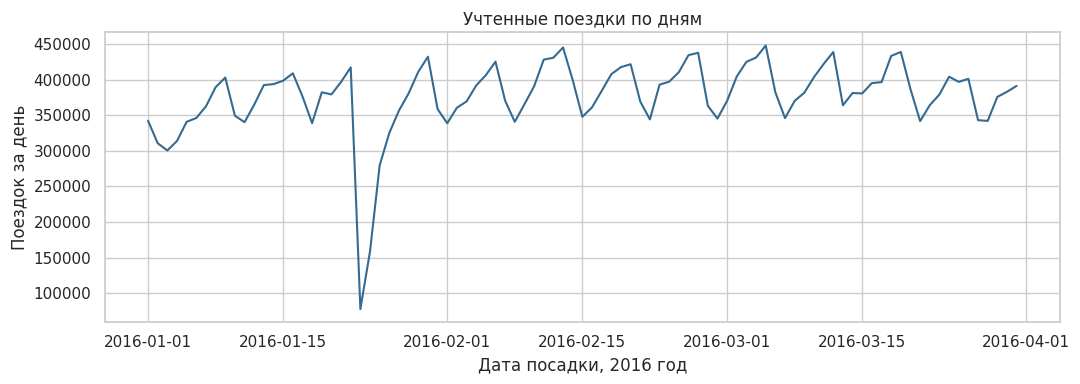

In [22]:
# Показываем дневную неоднородность, которую скрывают месячные итоги
daily_summary = report.groupby("trip_date", as_index=False)["trip_count"].sum()
fig, ax = plt.subplots(figsize=(11, 4))
sns.lineplot(data=daily_summary, x="trip_date", y="trip_count", color="#356a91", ax=ax)
ax.set(title="Учтенные поездки по дням", xlabel="Дата посадки, 2016 год", ylabel="Поездок за день")
ax.ticklabel_format(axis="y", style="plain")
fig.tight_layout()
fig.savefig("assets/daily_trips.png", dpi=160, bbox_inches="tight")
plt.show()

### 6.1. Как меняется время пика

Общий профиль показывает часы максимальной нагрузки в имеющихся записях. Затем проверю, применим ли один и тот же час к основным зонам посадки и сохраняется ли различие между месяцами.

In [23]:
# Сравниваем часы при одинаковом знаменателе внутри каждого типа дня
day_counts = calendar.groupby("day_type").size().rename("calendar_days").reset_index()
hourly_profile = report.groupby(["day_type", "pickup_hour"], as_index=False)["trip_count"].sum()
hourly_profile = hourly_profile.merge(day_counts, on="day_type", validate="many_to_one")
hourly_profile["trips_per_day"] = hourly_profile["trip_count"] / hourly_profile["calendar_days"]
peak_hours = (
    hourly_profile.sort_values(["day_type", "trips_per_day", "pickup_hour"], ascending=[True, False, True])
    .groupby("day_type", as_index=False).head(1)
)
peak_hours[["day_type", "calendar_days", "pickup_hour", "trips_per_day"]].rename(
    columns={"day_type": "Тип дня", "calendar_days": "Дней", "pickup_hour": "Час пика", "trips_per_day": "Поездок в час пика за день"}
).round(1)

,Тип дня,Дней,Час пика,Поездок в час пика за день
19,Будни,65,19,24863.3
42,Выходные,26,18,22021.9


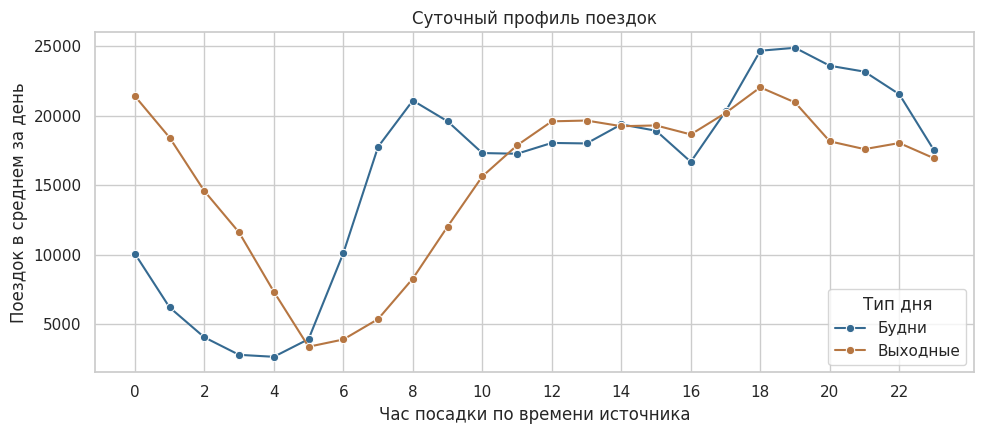

In [24]:
# Показываем различие суточного профиля будней и выходных
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.lineplot(data=hourly_profile, x="pickup_hour", y="trips_per_day", hue="day_type", hue_order=["Будни", "Выходные"], palette=["#356a91", "#b67642"], marker="o", ax=ax)
ax.set(title="Суточный профиль поездок", xlabel="Час посадки по времени источника", ylabel="Поездок в среднем за день")
ax.set_xticks(range(0, 24, 2))
ax.legend(title="Тип дня")
fig.tight_layout()
fig.savefig("assets/hourly_profile.png", dpi=160, bbox_inches="tight")
plt.show()

In [25]:
# Ранжируем зоны и считаем их вклад в общий объем, включая неизвестную зону в знаменателе
zone_summary_query = """
WITH zone_totals AS (
    SELECT pickup_zone, sum(trip_count) AS trips
    FROM zone_hourly_report
    WHERE trip_date >= :period_start AND trip_date < :period_end
        AND pickup_zone != 'Не определено'
    GROUP BY pickup_zone
), totals AS (
    SELECT sum(trip_count) AS all_trips FROM zone_hourly_report
    WHERE trip_date >= :period_start AND trip_date < :period_end
)
SELECT pickup_zone, trips,
    100.0 * trips / all_trips AS share_pct,
    100.0 * sum(trips) OVER (
        ORDER BY trips DESC, pickup_zone ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
    ) / all_trips AS cumulative_share_pct
FROM zone_totals CROSS JOIN totals
ORDER BY trips DESC, pickup_zone
"""
zone_summary = pd.read_sql_query(zone_summary_query, connection, params={"period_start": period_start, "period_end": period_end})
zone_summary.head(8).rename(columns={
    "pickup_zone": "Зона посадки", "trips": "Поездок", "share_pct": "Доля, %", "cumulative_share_pct": "Накопленная доля, %"
}).round(2)

,Зона посадки,Поездок,"Доля, %","Накопленная доля, %"
0,Midtown-Midtown South,5978820,17.44,17.44
1,Hudson Yards-Chelsea-Flatiron-Union Square,3177357,9.27,26.71
2,Upper East Side-Carnegie Hill,2457601,7.17,33.87
3,West Village,2294469,6.69,40.57
4,Turtle Bay-East Midtown,2273736,6.63,47.20
5,Upper West Side,1750753,5.11,52.30
6,SoHo-TriBeCa-Civic Center-Little Italy,1575423,4.60,56.90
7,Murray Hill-Kips Bay,1554480,4.53,61.43


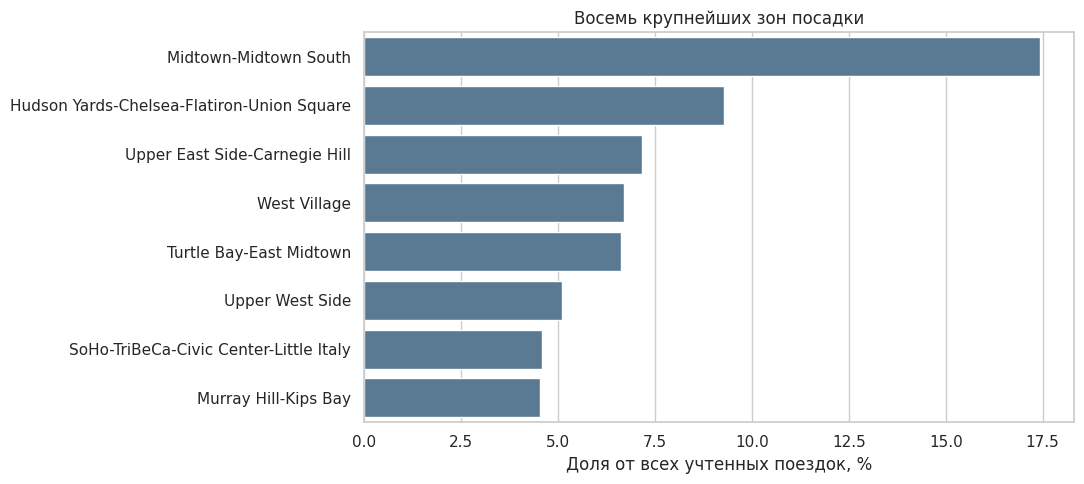

In [26]:
# Показываем зоны с наибольшим вкладом в отчетные поездки
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=zone_summary.head(8), y="pickup_zone", x="share_pct", color="#507c9b", ax=ax)
ax.set(title="Восемь крупнейших зон посадки", xlabel="Доля от всех учтенных поездок, %", ylabel="")
fig.tight_layout()
fig.savefig("assets/top_zones.png", dpi=160, bbox_inches="tight")
plt.show()

In [27]:
# Проверяем время пика отдельно для пяти крупнейших зон
leading_zones = zone_summary.head(5)["pickup_zone"].tolist()
zone_hourly = report.query("pickup_zone in @leading_zones").groupby(["pickup_zone", "day_type", "pickup_hour"], as_index=False)["trip_count"].sum()
zone_hourly = zone_hourly.merge(day_counts, on="day_type", validate="many_to_one")
zone_hourly["trips_per_day"] = zone_hourly["trip_count"] / zone_hourly["calendar_days"]
zone_hourly["hour_share_pct"] = zone_hourly["trip_count"] / zone_hourly.groupby(["pickup_zone", "day_type"])["trip_count"].transform("sum") * 100
zone_peaks = (
    zone_hourly.sort_values(["pickup_zone", "day_type", "trip_count", "pickup_hour"], ascending=[True, True, False, True])
    .groupby(["pickup_zone", "day_type"], as_index=False).head(1)
)
zone_peak_table = zone_peaks.pivot(index="pickup_zone", columns="day_type", values="pickup_hour").reindex(leading_zones)
zone_peak_table.rename_axis(index="Зона посадки", columns="Тип дня")

Тип дня,Будни,Выходные
Зона посадки,,
Midtown-Midtown South,19,18
Hudson Yards-Chelsea-Flatiron-Union Square,19,18
Upper East Side-Carnegie Hill,18,12
West Village,21,1
Turtle Bay-East Midtown,18,18


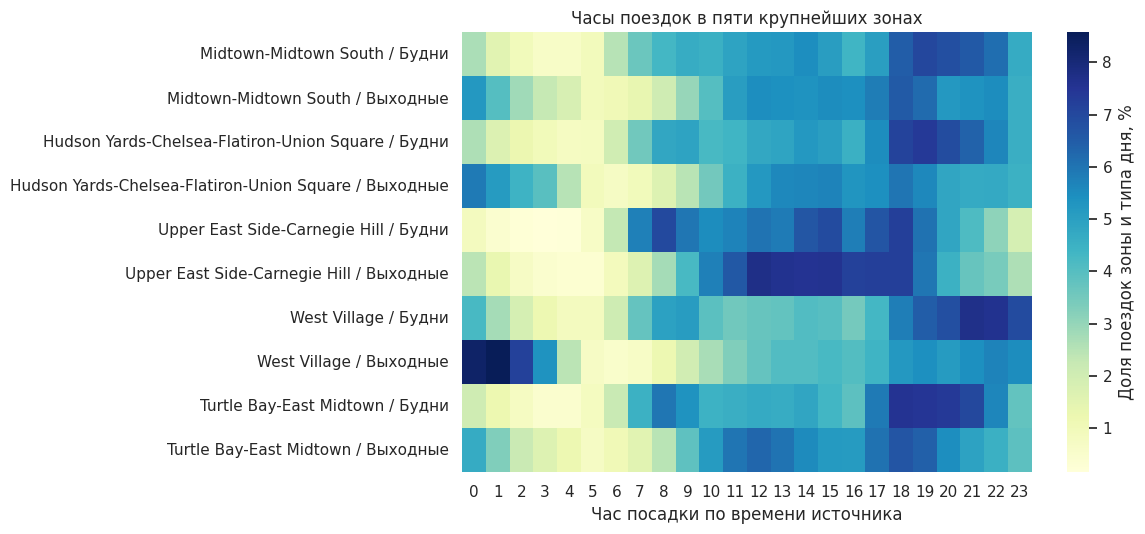

In [28]:
# Сравниваем распределение часов внутри зон с разным объемом поездок
zone_heatmap = zone_hourly.pivot(index=["pickup_zone", "day_type"], columns="pickup_hour", values="hour_share_pct")
zone_order = [(zone, day_type) for zone in leading_zones for day_type in ["Будни", "Выходные"]]
zone_heatmap = zone_heatmap.reindex(zone_order)
zone_heatmap.index = [zone + " / " + day_type for zone, day_type in zone_heatmap.index]
fig, ax = plt.subplots(figsize=(12, 5.5))
sns.heatmap(zone_heatmap, cmap="YlGnBu", cbar_kws={"label": "Доля поездок зоны и типа дня, %"}, ax=ax)
ax.set(title="Часы поездок в пяти крупнейших зонах", xlabel="Час посадки по времени источника", ylabel="")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig("assets/zone_hour_profile.png", dpi=160, bbox_inches="tight")
plt.show()

In [29]:
# Проверяем, повторяется ли различие пиков в каждом месяце
monthly_hourly = report.groupby(["month", "day_type", "pickup_hour"], as_index=False)["trip_count"].sum()
monthly_peaks = (
    monthly_hourly.sort_values(["month", "day_type", "trip_count", "pickup_hour"], ascending=[True, True, False, True])
    .groupby(["month", "day_type"], as_index=False).head(1)
)
monthly_peak_table = monthly_peaks.pivot(index="month", columns="day_type", values="pickup_hour")
monthly_peak_table.rename_axis(index="Месяц", columns="Тип дня")

Тип дня,Будни,Выходные
Месяц,,
2016-01,19,18
2016-02,19,18
2016-03,19,0


In [30]:
# Проверяем устойчивость районных профилей в каждом из трех месяцев
zone_monthly_hourly = report.query("pickup_zone in @leading_zones").groupby(
    ["pickup_zone", "month", "day_type", "pickup_hour"], as_index=False
)["trip_count"].sum()
zone_monthly_peaks = (
    zone_monthly_hourly.sort_values(["pickup_zone", "month", "day_type", "trip_count", "pickup_hour"], ascending=[True, True, True, False, True])
    .groupby(["pickup_zone", "month", "day_type"], as_index=False).head(1)
)
zone_monthly_peak_table = zone_monthly_peaks.pivot(index=["pickup_zone", "month"], columns="day_type", values="pickup_hour")
zone_monthly_peak_table.rename_axis(index=["Зона посадки", "Месяц"], columns="Тип дня")

Тип дня                                             Будни  Выходные
Зона посадки                               Месяц                   
Hudson Yards-Chelsea-Flatiron-Union Square 2016-01     19        15
                                           2016-02     19        18
                                           2016-03     19         0
Midtown-Midtown South                      2016-01     19        18
                                           2016-02     19        18
                                           2016-03     19        18
Turtle Bay-East Midtown                    2016-01     18        18
                                           2016-02     19        18
                                           2016-03     18        19
Upper East Side-Carnegie Hill              2016-01     18        15
                                           2016-02     18        12
                                           2016-03     18        13
West Village                               2016-01     22         1
                                           2016-02     21         1
                                           2016-03     21         1

In [31]:
# Оцениваем ночную долю поездок West Village при разных типах дня
west_village = report.query("pickup_zone == 'West Village'")
night_profile = west_village.groupby("day_type", as_index=False)["trip_count"].sum().rename(columns={"trip_count": "all_trips"})
night_counts = west_village.query("pickup_hour < 4").groupby("day_type", as_index=False)["trip_count"].sum().rename(columns={"trip_count": "night_trips"})
night_profile = night_profile.merge(night_counts, on="day_type", validate="one_to_one")
night_profile["night_share_pct"] = night_profile["night_trips"] / night_profile["all_trips"] * 100
night_profile.rename(columns={"day_type": "Тип дня", "all_trips": "Всего поездок зоны", "night_trips": "Поездок с 00:00 до 03:59", "night_share_pct": "Ночная доля, %"}).round(2)

,Тип дня,Всего поездок зоны,Поездок с 00:00 до 03:59,"Ночная доля, %"
0,Будни,1505544,152196,10.11
1,Выходные,788925,232138,29.42


### 6.2. Чувствительность к спорным записям

Очень большие суммы не удаляю автоматически: по агрегированному источнику нельзя надежно установить их природу. Покажу вклад записей с начислением более 500 USD. Это диагностическая граница, а не доказательство ошибки и не новое правило основного отчета.

Для длительности сравню основной предел 24 часа с пределом 6 часов. Проверка нужна, чтобы понять, меняется ли время пика от этого решения.

In [32]:
# Оцениваем вклад больших начислений и длительных записей
sensitivity = pd.DataFrame({
    "Показатель": ["Поездок с начислением более 500 USD", "Их доля в количестве, %", "Их доля в сумме начислений, %", "Записей длительностью более 6 часов", "Их доля в количестве, %"],
    "Значение": [report["high_amount_records"].sum(),
        report["high_amount_records"].sum() / report["trip_count"].sum() * 100,
        report["high_amount_cents"].sum() / report["total_amount_cents"].sum() * 100,
        report["over_6h_records"].sum(),
        report["over_6h_records"].sum() / report["trip_count"].sum() * 100]
})
sensitivity.round(5)

,Показатель,Значение
0,Поездок с начислением более 500 USD,181.00000
1,"Их доля в количестве, %",0.00053
2,"Их доля в сумме начислений, %",0.17696
3,Записей длительностью более 6 часов,50919.00000
4,"Их доля в количестве, %",0.14852


In [33]:
# Пересчитываем пики после исключения записей длительностью более 6 часов
alternative = report.copy()
alternative["trip_count"] = alternative["trip_count"] - alternative["over_6h_records"]
alternative_hourly = alternative.groupby(["day_type", "pickup_hour"], as_index=False)["trip_count"].sum()
alternative_peaks = (
    alternative_hourly.sort_values(["day_type", "trip_count", "pickup_hour"], ascending=[True, False, True])
    .groupby("day_type", as_index=False).head(1)
)
peak_sensitivity = peak_hours[["day_type", "pickup_hour"]].merge(
    alternative_peaks[["day_type", "pickup_hour"]], on="day_type", validate="one_to_one", suffixes=("_24h", "_6h")
)
peak_sensitivity

,day_type,pickup_hour_24h,pickup_hour_6h
0,Будни,19,19
1,Выходные,18,18


## 7. Результат и ограничения

Из 68 999 718 исходных строк получено 34 499 856 уникальных сочетаний полей. После последовательных правил отбора в отчет вошло 34 285 210 поездок. Все дневные количества и суммы сошлись с отдельным SQL-запросом к источнику. В SQLite сохранено 180 261 строка с детализацией «дата - час - зона».

Пять крупнейших зон дают 47,20% всех учтенных поездок. Общий максимум за квартал приходится на 19:00 в будни и 18:00 в выходные, но один час не описывает весь город. В West Village пик выходных приходится на 01:00 во всех трех месяцах. Доля поездок этой зоны между 00:00 и 03:59 возрастает с 10,11% в будни до 29,42% в выходные. В Upper East Side-Carnegie Hill максимум выходных расположен между 12:00 и 15:00, а в будни - в 18:00.

Разница между зонами устойчивее единого городского часа: общий пик выходных в марте смещается на 00:00. Поэтому в регулярном отчете стоит сохранять срез «зона - тип дня - час» и показывать соседние часы, а не только один максимум. Это помогает выбрать зоны и временные интервалы для последующей операционной проверки. Для решений о количестве машин нужны данные о свободном парке, отказах и ожидании пассажиров.

Более строгий предел длительности 6 часов исключает 50 919 записей, или 0,149% основной выборки. Общие часы пика остаются теми же. Начисления свыше 500 USD встречаются у 181 поездки и формируют 0,177% суммы поля `total_amount`. Их стоит проверять отдельно перед финансовым использованием отчета. В январе также есть резкий дневной провал: 23 января учтено 77 384 поездки. Причина по этим данным не устанавливается.

Названия зон отсутствуют у 1,49% учтенных поездок. Эти записи остаются в общих итогах, поэтому доли известных зон считаются от всей отчетной выборки. Итоги относятся к историческому демонстрационному набору и выбранному правилу удаления полных повторов.

Технический результат - повторяемая пакетная загрузка с ручным запуском ноутбука. Повторная обработка периода сохраняет дневные контрольные показатели, ошибка вставки откатывает удаление, а журнал фиксирует успешные загрузки.

In [34]:
# Закрываем подключение после построения отчета
connection.close()
print("Подключение к SQLite закрыто")

Подключение к SQLite закрыто
